In [20]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
default_of_credit_card_clients = fetch_ucirepo(id=350) 
  
# data (as pandas dataframes) 
X = default_of_credit_card_clients.data.features 
y = default_of_credit_card_clients.data.targets 
  
# metadata 
print(default_of_credit_card_clients.metadata) 
  
# variable information 
print(default_of_credit_card_clients.variables) 

df = pd.concat([X, y], axis=1)


{'uci_id': 350, 'name': 'Default of Credit Card Clients', 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients', 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv', 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.", 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 30000, 'num_features': 23, 'feature_types': ['Integer', 'Real'], 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'], 'target_col': ['Y'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C55S3H', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 365, 'type': 'NATIVE', 'title': 'The comparisons of data mining techniques for the predictive accuracy of 

In [22]:
#Exploratory Data Analysis (EDA)
print("Shape:", df.shape)
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

summary = df.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

print(summary)

Shape: (30000, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int

           Count  Percentage (%)
Age_Group                       
Under 21       0        0.000000
21-30      11013       36.710000
31-50      16718       55.726667
51-79       2269        7.563333


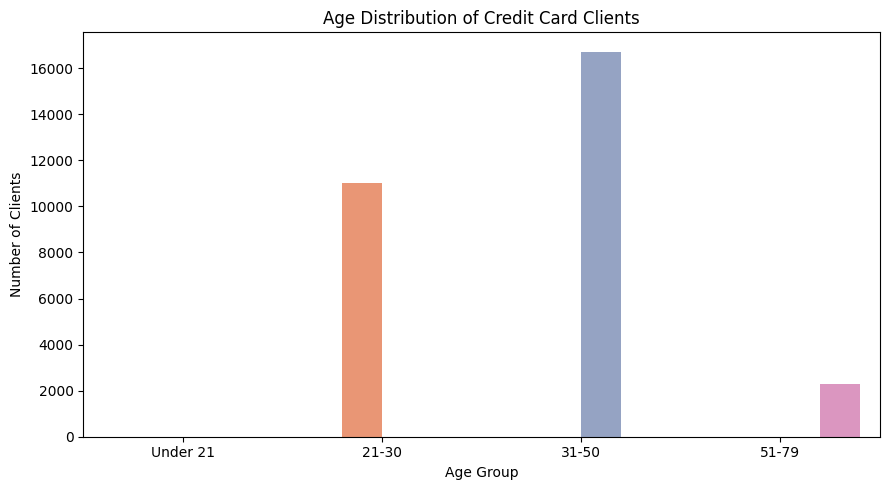

In [23]:
import pandas as pd

eda = df.copy()

age_bins = [0, 20, 30, 50, 80]
age_labels = ["Under 21", "21-30", "31-50", "51-79"]

eda["Age_Group"] = pd.cut(
    eda["X5"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_summary = eda["Age_Group"].value_counts().sort_index()

age_distribution = pd.DataFrame({
    "Count": age_summary,
    "Percentage (%)": age_summary / len(eda) * 100
})

print(age_distribution)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda,
    x="Age_Group",
    hue="Age_Group",
    palette="Set2",
    legend=False
)

plt.title("Age Distribution of Credit Card Clients")
plt.xlabel("Age Group")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

In [24]:
age_risk = eda.groupby(
    "Age_Group",
    observed=True
).agg(
    Total_Clients=("Y", "count"),
    Default_Count=("Y", "sum"),
    Default_Rate=("Y", "mean")
)

age_risk["Default_Rate"] *= 100

print(age_risk)

           Total_Clients  Default_Count  Default_Rate
Age_Group                                            
21-30              11013           2471     22.437120
31-50              16718           3588     21.461897
51-79               2269            577     25.429705


Education
University         14030
Graduate school    10585
High school         4917
Unknown (5)          280
Others               123
Unknown (6)           51
Unknown (0)           14
Name: count, dtype: int64


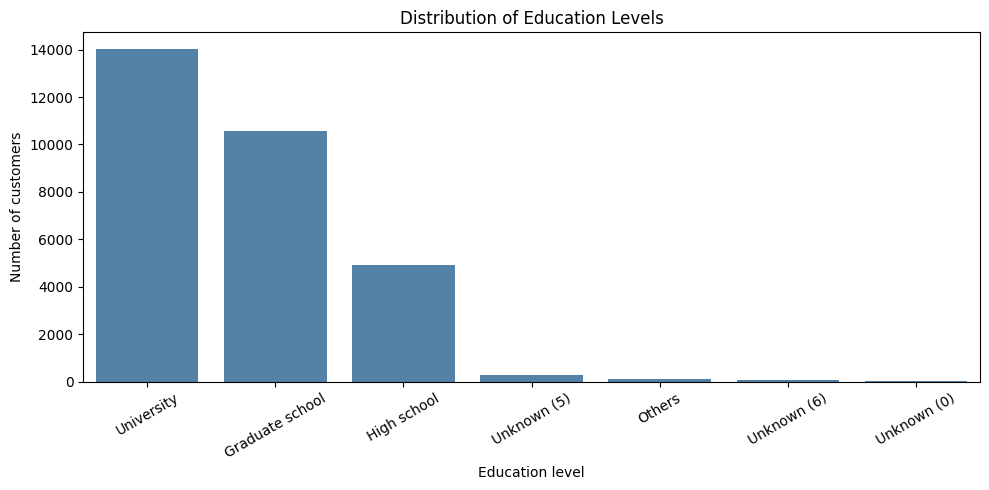

In [25]:
eda = df.copy()

education_map = {
    1: "Graduate school",
    2: "University",
    3: "High school",
    4: "Others",
    0: "Unknown (0)",
    5: "Unknown (5)",
    6: "Unknown (6)"
}

eda["Education"] = eda["X3"].map(education_map)
eda["Education"] = eda["Education"].fillna("Unmapped")

summary = eda["Education"].value_counts()
print(summary)

fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(
    data=eda,
    x="Education",
    order=summary.index,
    color="steelblue",
    ax=ax
)

ax.set_xlabel("Education level")
ax.set_ylabel("Number of customers")
ax.set_title("Distribution of Education Levels")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

                 customers  default_rate
Education                               
High school           4917     25.157616
University           14030     23.734854
Graduate school      10585     19.234766
Unknown (6)             51     15.686275
Unknown (5)            280      6.428571
Others                 123      5.691057
Unknown (0)             14      0.000000


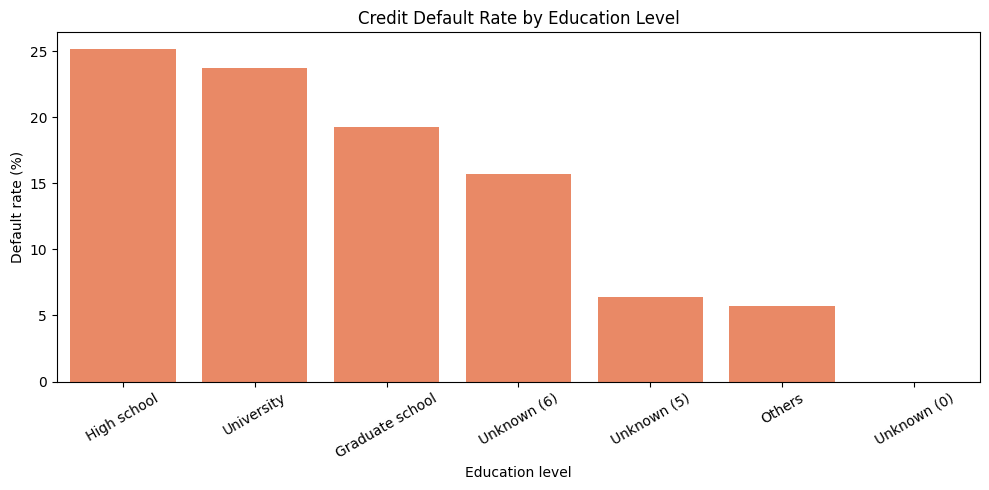

In [26]:

default_rate = (
    eda.groupby("Education")["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "customers",
        "mean": "default_rate"
    })
    .sort_values("default_rate", ascending=False)
)

default_rate["default_rate"] *= 100
print(default_rate)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=default_rate.reset_index(),
    x="Education",
    y="default_rate",
    color="coral"
)

plt.ylabel("Default rate (%)")
plt.xlabel("Education level")
plt.title("Credit Default Rate by Education Level")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


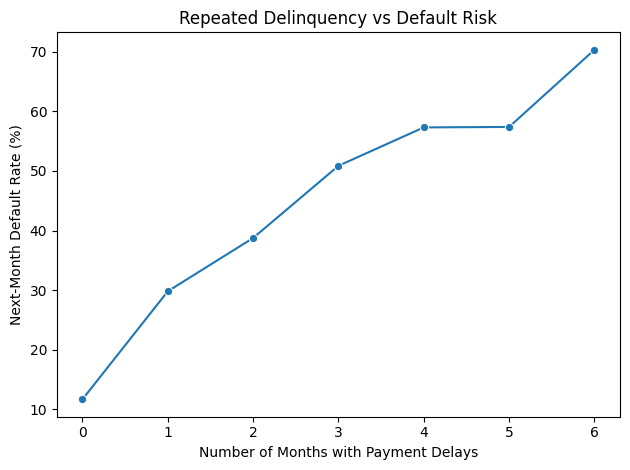

In [27]:

payment_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

# Count months with reported repayment delays
eda["months_late"] = (
    eda[payment_cols] >= 1
).sum(axis=1)

# Flag serious delinquency in any historical month
eda["ever_2plus"] = (
    eda[payment_cols] >= 2
).any(axis=1)

risk_summary = (
    eda.groupby("months_late")
    .agg(
        customers=("Y", "size"),
        default_rate=("Y", "mean")
    )
    .reset_index()
)

risk_summary["default_rate"] *= 100

sns.lineplot(
    data=risk_summary,
    x="months_late",
    y="default_rate",
    marker="o"
)

plt.xlabel("Number of Months with Payment Delays")
plt.ylabel("Next-Month Default Rate (%)")
plt.title("Repeated Delinquency vs Default Risk")
plt.tight_layout()
plt.show()


In [28]:

eda["credit_limit_band"] = pd.qcut(
    eda["X1"],
    q=4,
    duplicates="drop"
)

credit_summary = (
    eda.groupby(
        "credit_limit_band",
        observed=True
    )
    .agg(
        customers=("Y", "size"),
        default_rate=("Y", "mean"),
        avg_limit=("X1", "mean")
    )
)

credit_summary["default_rate"] *= 100

print(credit_summary.round(2))



                       customers  default_rate  avg_limit
credit_limit_band                                        
(9999.999, 50000.0]         7676         31.79   35204.79
(50000.0, 140000.0]         7614         24.72   97301.02
(140000.0, 240000.0]        7643         17.35  192429.67
(240000.0, 1000000.0]       7067         13.98  359800.15


        Count  Percentage (%)
Gender                       
Female  18112       60.373333
Male    11888       39.626667


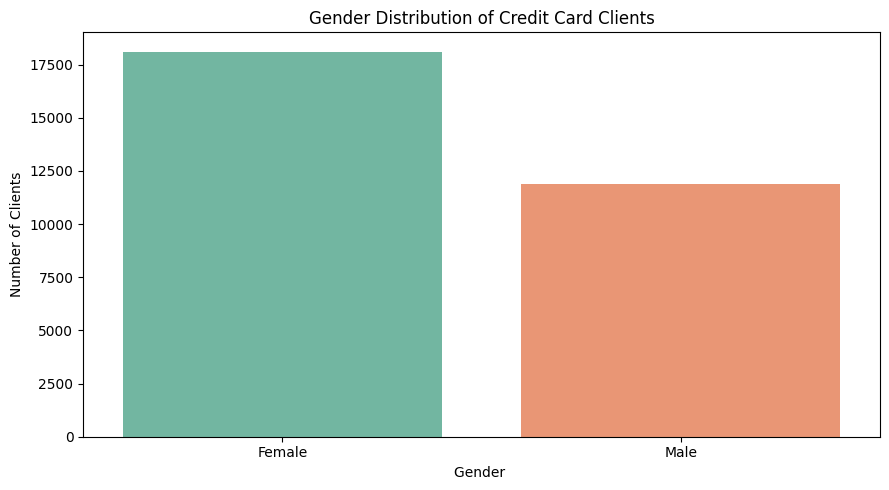

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
eda = df.copy()

age_bins = [1,2]
age_labels = ["Male", "Female"]

gender_map = {
    1: "Male",
    2: "Female"
}

eda["Gender"] = eda["X2"].map(gender_map).fillna("Unknown")

age_summary = eda["Gender"].value_counts().sort_index()

age_distribution = pd.DataFrame({
    "Count": age_summary,
    "Percentage (%)": age_summary / len(eda) * 100
})

print(age_distribution)


plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda,
    x="Gender",
    hue="Gender",
    palette="Set2",
    legend=False
)

plt.title("Gender Distribution of Credit Card Clients")
plt.xlabel("Gender ")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

        customers  default_rate
Gender                         
Male        11888     24.167227
Female      18112     20.776281


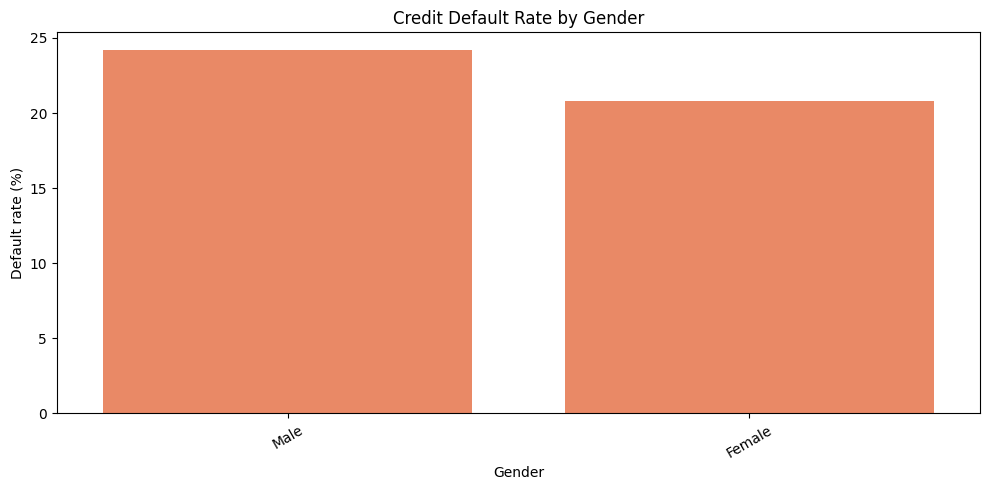

In [32]:
default_rate = (
    eda.groupby("Gender")["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "customers",
        "mean": "default_rate"
    })
    .sort_values("default_rate", ascending=False)
)

default_rate["default_rate"] *= 100
print(default_rate)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=default_rate.reset_index(),
    x="Gender",
    y="default_rate",
    color="coral"
)

plt.ylabel("Default rate (%)")
plt.xlabel("Gender")
plt.title("Credit Default Rate by Gender")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
